## Analysing snippets

In [1]:
import pandas as pd
from driver import clean_text, get_text_stats
import numpy as np
import re

results_navigation = pd.read_csv("Data/results_navigation.csv")
results_navigation["timestamp"] = pd.to_datetime(results_navigation["timestamp"])

results_navigation["snippet"] = results_navigation["snippet"].apply(lambda x: clean_text(x))
# results_navigation["snippet"] = results_navigation["snippet"].apply(lambda x: re.sub(
#     r'^(Jan|Feb|Mar|Apr|May|Jun|Jul|Aug|Sep|Sept|Oct|Nov|Dec)\s+\d{1,2},\s+\d{4}\s*(?:\.\.\.)?\s*',
#     '',
#     x,
#     flags=re.IGNORECASE
# ))
results_navigation["snippet"] = results_navigation["snippet"].apply(lambda x: x.strip())
results_navigation["SERP_result"] = [str(title).strip()+snippet for title, snippet in zip(results_navigation["title"], results_navigation["snippet"])]

text_stat_results = get_text_stats(results_navigation, "SERP_result")

results_navigation["SERP_result_content_len"] = text_stat_results["content_len"]
results_navigation["SERP_result_mean_aoa"] = text_stat_results["mean_aoa"]
results_navigation["SERP_result_mean_conc"] = text_stat_results["mean_conc"]
results_navigation["SERP_result_gulpease_index"] = text_stat_results["gulpease_index"]
# results_navigation["snippet_fres"] = text_stat_results["fres"]

  0%|          | 0/930 [00:00<?, ?it/s]

In [2]:
results_navigation.to_csv("Data/results_navigation.csv", index=False, encoding='utf8')

In [3]:
results_navigation.loc[pd.isna(results_navigation["rank"])]

,uid,topic_number,qid,query,serp_id,url,title,snippet,rank,relevance_score,click_count,timestamp,SERP_result,SERP_result_content_len,SERP_result_mean_aoa,SERP_result_mean_conc,SERP_result_gulpease_index


## Analysing navigation

In [49]:
import pandas as pd

# nlp = spacy.load("it_core_news_lg")
navigation_quality = pd.read_csv("Data/navigation_quality.csv")
navigation_quality["last_relevant_timestamp"] = pd.to_datetime(navigation_quality["last_relevant_timestamp"])
tail_ratio = []
for i, row in navigation_quality.iterrows():
    if row["total_clicks"] > 0:
        tail_ratio.append(row["tail"]/row["total_clicks"])
    else:
        tail_ratio.append(None)
navigation_quality["tail_ratio"] = tail_ratio

effective_nav = []
effective_nav_pt2 = []
for nav_eff, tail_ratio in zip(navigation_quality["nav_eff"], navigation_quality["tail_ratio"]):
    if pd.isna(nav_eff):
        effective_nav.append(None)
    else:
        effective_nav.append(int(nav_eff >= 0.8))
    if pd.isna(tail_ratio):
        effective_nav_pt2.append(None)
    else:
        effective_nav_pt2.append(int(tail_ratio<0.2))

navigation_quality["effective_nav"] = effective_nav
navigation_quality["effective_nav_pt2"] = effective_nav_pt2

navigation_quality.to_csv("Data/navigation_quality.csv", index=False, encoding="utf8")

serp_df = pd.read_csv("Data/results_navigation.csv")

query_df = pd.read_csv("Data/query_df.csv")
query_df["timestamp"] = pd.to_datetime(query_df["timestamp"])

click_df = pd.read_csv("Data/clicked_results_df.csv")
click_df["timestamp"] = pd.to_datetime(click_df["timestamp"])

view_df = pd.read_csv("Data/viewed_results_df.csv")
view_df["timestamp"] = pd.to_datetime(view_df["timestamp"])
view_df["associated_click_timestamp"] = pd.to_datetime(view_df["associated_click_timestamp"])

In [50]:
navigation_quality["serp_id"].unique()

array(['serp1', 'serp2', 'serp3', 'serp4', 'serp5', 'serp6', 'serp7',
       'serp8', 'serp9', 'serp10', 'serp11', 'serp12', 'serp13', 'serp14',
       'serp15', 'serp16', 'serp17', 'serp18', 'serp19', 'serp22',
       'serp23', 'serp27', 'serp28', 'serp30', 'serp31', 'serp32',
       'serp33', 'serp34', 'serp35', 'serp36', 'serp37', 'serp38',
       'serp39', 'serp40', 'serp41', 'serp42', 'serp43', 'serp44',
       'serp45', 'serp50', 'serp51', 'serp52', 'serp53', 'serp54',
       'serp55', 'serp56', 'serp57', 'serp59', 'serp60', 'serp61',
       'serp62', 'serp63', 'serp64', 'serp65', 'serp66', 'serp67',
       'serp68', 'serp69', 'serp70', 'serp71', 'serp72', 'serp73',
       'serp74', 'serp75', 'serp78', 'serp79', 'serp80', 'serp81',
       'serp82', 'serp83', 'serp84', 'serp85', 'serp86', 'serp87',
       'serp88', 'serp89', 'serp90', 'serp91', 'serp92', 'serp93',
       'serp95', 'serp96', 'serp97', 'serp99', 'serp100', 'serp101',
       'serp102', 'serp103', 'serp104', 'serp105'

In [51]:
navigation_quality.loc[navigation_quality["serp_id"]=="serp35"]

,uid,topic_number,qid,query,serp_id,total_clicks,repetitions,tail,last_relevant_timestamp,nav_eff,...,viewed_avg_aoa,viewed_avg_conc,viewed_avg_length,viewed_avg_gulpease_index,SERP_avg_aoa,SERP_avg_conc,SERP_avg_gulpease_index,SERP_avg_length,tail_ratio,effective_nav_pt2
28,6,g3t3,q35,Quali sono 5 animali tipici dell'india,serp35,1,0,0,2026-05-19 14:56:05.417,1.0,...,NaN,NaN,NaN,NaN,5.872435,6.279792,65.667066,33.8,0.0,1.0


In [52]:
view_df["serp_id"].unique()

array(['serp1', 'serp2', 'serp3', 'serp4', 'serp5', 'serp6', 'serp7',
       'serp8', 'serp9', 'serp10', 'serp11', 'serp12', 'serp13', 'serp14',
       'serp15', 'serp16', 'serp17', 'serp18', 'serp19', 'serp22',
       'serp23', 'serp27', 'serp28', 'serp30', 'serp31', 'serp32',
       'serp33', 'serp34', 'serp36', 'serp37', 'serp38', 'serp39',
       'serp40', 'serp41', 'serp42', 'serp43', 'serp44', 'serp45',
       'serp50', 'serp51', 'serp52', 'serp53', 'serp54', 'serp55',
       'serp56', 'serp57', 'serp59', 'serp60', 'serp61', 'serp62',
       'serp63', 'serp64', 'serp65', 'serp66', 'serp67', 'serp68',
       'serp69', 'serp70', 'serp71', 'serp72', 'serp73', 'serp74',
       'serp75', 'serp78', 'serp79', 'serp80', 'serp81', 'serp82',
       'serp83', 'serp84', 'serp85', 'serp86', 'serp87', 'serp88',
       'serp89', 'serp90', 'serp91', 'serp92', 'serp93', 'serp95',
       'serp96', 'serp97', 'serp99', 'serp100', 'serp101', 'serp102',
       'serp103', 'serp104', 'serp105', 'serp106

In [53]:
import numpy as np

first_click_time = [] # time from query entry to first click
avg_scroll_time_before_click = [] # how much time is spent scrolling on SERP before a click
# avg_snippet_dwell_time = [] # average time for which a snippet is viewed at a time 
rank_lowest_view = [] # rank of the lowest viewed result
avg_snippet_view_counts_before_click = [] # average number of times a user views a snippet before making a click
avg_snippet_dwell_time_before_click = [] # average time a user dwells on a snippet at a time prior to making a click

# average text stats of all SERP results
SERP_avg_aoa = []
SERP_avg_conc = []
SERP_avg_length = []
SERP_avg_gulpease_index = []

# average text stats of all viewed results
viewed_avg_aoa = []
viewed_avg_conc = []
viewed_avg_length = []
viewed_avg_gulpease_index = []

for serp_id in navigation_quality["serp_id"]:
    query_temp_df = query_df.loc[query_df["serp_id"] == serp_id] # query that yielded the SERP
    click_temp_df = click_df.loc[click_df["serp_id"] == serp_id] # all the clicks done on this SERP
    serp_temp_df = serp_df.loc[serp_df["serp_id"]==serp_id] # all the SERP results
    view_temp_df = view_df.loc[(view_df["serp_id"]==serp_id) & (view_df["viewType"]=="resultExposureEnded")] # all the snippets viewed in a SERP

    rank_lowest_view.append(view_temp_df["rank"].max()) # the last ranked result viewed

    if len(click_temp_df)==0: # no clicks were made on this SERP
        first_click_time.append(None) 
        avg_scroll_time_before_click.append(None)
        avg_snippet_dwell_time_before_click.append(None)
        avg_snippet_view_counts_before_click.append(None)
    else:
        first_click_time.append((click_temp_df["timestamp"].min() - query_temp_df["timestamp"].min()).total_seconds()) # duration between query submission and first click
        if len(view_temp_df) == 0: # user did not view any results
            avg_scroll_time_before_click.append(None)
            avg_snippet_dwell_time_before_click.append(None)
            avg_snippet_view_counts_before_click.append(None)
        else:
            scroll_time_before_click = [] # duration of time spent scrolling on the SERP before clicking on a result
            snippet_dwell_time_before_scroll = [] # duration of time spent looking at a snippet at a time before clicking on a SERP result
            avg_snippet_view_counts = [] # number of times a snippet is viewed before a click

            for _, click in click_temp_df.iterrows():
                views_before_click = view_temp_df.loc[view_temp_df["associated_click_timestamp"]==click["timestamp"]] # all snippets viewed before a click was made
                
                scroll_time_before_click.append((click["timestamp"] - views_before_click["timestamp"].min()).total_seconds())
                snippet_dwell_time_before_scroll.append(np.mean(views_before_click["viewDurationInSeconds"].dropna()))
                avg_snippet_view_counts.append(views_before_click["rank"].value_counts().mean())

            avg_scroll_time_before_click.append(np.mean(scroll_time_before_click))
            avg_snippet_dwell_time_before_click.append(np.mean(snippet_dwell_time_before_scroll))
            avg_snippet_view_counts_before_click.append(np.mean(avg_snippet_view_counts))

    # if len(click_temp_df) <= 1:
    #     avg_dwell_time_before_click.append(0)
    # else:
    #     click_temp_df = click_df.loc[click_df["serp_id"] == serp_id]

    #     for i, clicks in click_temp_df[1:].iterrows():
    #         time_before_click.append((click_temp_df.iloc[i]["timestamp"]- click_temp_df.iloc[i-1]["timestamp"]).total_seconds())
    #     avg_dwell_time_before_click.append(np.mean(time_before_click))

    SERP_avg_aoa.append(pd.Series([aoa for aoa in serp_temp_df["SERP_result_mean_aoa"]]).mean())
    SERP_avg_conc.append(pd.Series([conc for conc in serp_temp_df["SERP_result_mean_conc"]]).mean())
    SERP_avg_gulpease_index.append(pd.Series([gulp_ind for gulp_ind in serp_temp_df["SERP_result_gulpease_index"]]).mean())
    SERP_avg_length.append(pd.Series([cont_len for cont_len in serp_temp_df["SERP_result_content_len"]]).mean())

    if len(view_temp_df) == 0:
        viewed_avg_aoa.append(None)
        viewed_avg_conc.append(None)
        viewed_avg_length.append(None)
        viewed_avg_gulpease_index.append(None)
    else:
        unique_viewed_results = serp_temp_df.loc[serp_temp_df["url"].isin(view_temp_df["url"].unique())]
        viewed_avg_aoa.append(unique_viewed_results["SERP_result_mean_aoa"].dropna().mean())
        viewed_avg_conc.append(unique_viewed_results["SERP_result_mean_conc"].dropna().mean())
        viewed_avg_length.append(unique_viewed_results["SERP_result_gulpease_index"].dropna().mean())
        viewed_avg_gulpease_index.append(unique_viewed_results["SERP_result_content_len"].dropna().mean())

navigation_quality["first_click_time"] = first_click_time
navigation_quality["avg_scroll_time_before_click"] = avg_scroll_time_before_click
navigation_quality["avg_snippet_dwell_time_before_click"] = avg_snippet_dwell_time_before_click
navigation_quality["avg_snippet_view_counts_before_click"] = avg_snippet_view_counts_before_click
navigation_quality["rank_lowest_view"] = rank_lowest_view

navigation_quality["viewed_avg_aoa"] = viewed_avg_aoa
navigation_quality["viewed_avg_conc"] = viewed_avg_conc
navigation_quality["viewed_avg_length"] = viewed_avg_length
navigation_quality["viewed_avg_gulpease_index"] = viewed_avg_gulpease_index

navigation_quality["SERP_avg_aoa"] = SERP_avg_aoa
navigation_quality["SERP_avg_conc"] = SERP_avg_conc
navigation_quality["SERP_avg_gulpease_index"] = SERP_avg_gulpease_index
navigation_quality["SERP_avg_length"] = SERP_avg_length

navigation_quality["last_relevant_timestamp"] = pd.to_datetime(navigation_quality["last_relevant_timestamp"])
navigation_quality.to_csv("Data/navigation_quality.csv", index=False, encoding="utf8")

In [54]:
navigation_quality.head()

,uid,topic_number,qid,query,serp_id,total_clicks,repetitions,tail,last_relevant_timestamp,nav_eff,...,viewed_avg_aoa,viewed_avg_conc,viewed_avg_length,viewed_avg_gulpease_index,SERP_avg_aoa,SERP_avg_conc,SERP_avg_gulpease_index,SERP_avg_length,tail_ratio,effective_nav_pt2
0,1,g3t3,q1,Quali sono i cinque animali tipici dell india,serp1,2,1,0,2026-05-19 14:53:19.408,0.5,...,5.632918,6.431042,66.377603,33.900000,5.632918,6.431042,66.377603,33.900,0.0,1.0
1,1,g3t2,q2,Quale è il nome del simbolo al centro della ba...,serp2,1,0,0,2026-05-19 15:02:48.776,1.0,...,4.690000,6.150000,61.852665,32.000000,4.690000,6.150000,61.852665,32.000,0.0,1.0
2,1,g3t1,q3,Fiume sacro degli indiani,serp3,1,0,0,2026-05-19 15:08:58.405,1.0,...,4.775000,7.241667,47.423141,37.500000,4.974583,7.119792,55.810356,34.625,0.0,1.0
3,2,g3t3,q4,Quali sono i animali dall'India,serp4,0,0,0,NaT,NaN,...,4.723333,7.862500,78.369688,35.000000,5.252222,6.732812,64.844950,31.600,NaN,NaN
4,2,g3t3,q5,Quali sono i 5 animali tipici dall'India,serp5,1,0,0,2026-05-19 14:52:53.759,1.0,...,6.322413,6.267333,69.293081,32.857143,5.786159,6.757083,69.356585,33.700,0.0,1.0


In [55]:
navigation_quality.loc[navigation_quality["serp_id"]=="serp15"]

,uid,topic_number,qid,query,serp_id,total_clicks,repetitions,tail,last_relevant_timestamp,nav_eff,...,viewed_avg_aoa,viewed_avg_conc,viewed_avg_length,viewed_avg_gulpease_index,SERP_avg_aoa,SERP_avg_conc,SERP_avg_gulpease_index,SERP_avg_length,tail_ratio,effective_nav_pt2
14,4,g3t2,q15,Quale il simbolo dell'India,serp15,0,0,0,NaT,NaN,...,5.54763,5.799074,68.143134,34.3,5.54763,5.799074,68.143134,34.3,NaN,NaN


## Visualisation

In [1]:
import pandas as pd

navigation_quality = pd.read_csv("Data/navigation_quality.csv")
categories = [
    "first_click_time", "avg_scroll_time_before_click", "avg_snippet_dwell_time_before_click", "avg_snippet_view_counts_before_click", "rank_lowest_view", 
    "viewed_avg_length", "viewed_avg_gulpease_index", "viewed_avg_conc", "viewed_avg_aoa",
    # "SERP_avg_length", "SERP_avg_gulpease_index", "SERP_avg_conc", "SERP_avg_aoa"
]
# navigation_quality

### RQ1

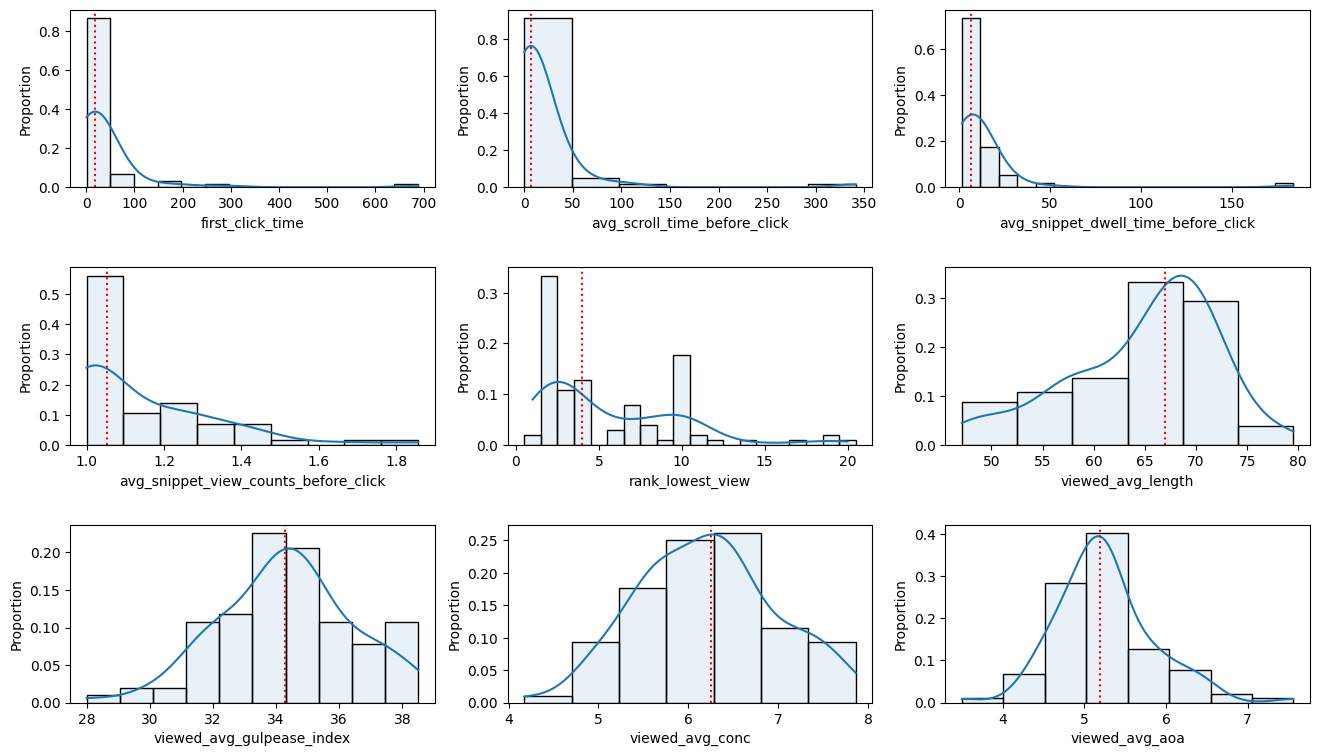

,category,mean,std_dev,max,min,median,modes
0,first_click_time,42.960610,98.420228,688.605000,0.752000,18.880000,"[0.752, 1.442, 3.171, 3.369, 4.61, 5.424, 5.73..."
1,avg_scroll_time_before_click,18.623926,48.068321,341.061000,0.002000,7.046200,[0.003]
2,avg_snippet_dwell_time_before_click,12.583515,24.504127,183.789667,1.574333,6.613229,"[1.5743333333333334, 1.77, 3.3635, 3.619744444..."
3,avg_snippet_view_counts_before_click,1.142713,0.188576,1.857143,1.000000,1.052778,[1.0]
4,rank_lowest_view,5.617647,4.286853,20.000000,1.000000,4.000000,[2.0]
5,viewed_avg_length,64.888723,7.198763,79.525876,47.114628,66.920593,[70.00657894736842]
6,viewed_avg_gulpease_index,34.326479,2.100241,38.500000,28.000000,34.292857,"[34.0, 35.0]"
7,viewed_avg_conc,6.205167,0.761402,7.862500,4.175000,6.249722,[5.578125]
8,viewed_avg_aoa,5.251159,0.595631,7.560000,3.500000,5.192867,[5.155777777777778]


In [3]:
from driver import get_descriptive_stats


binwidth_map = {
    "first_click_time": 50,
    "avg_scroll_time_before_click": 50,
    "avg_snippet_dwell_time_before_click": 10,
    "avg_snippet_view_counts_before_click": 0.1,
    "rank_lowest_view": 1,
    "viewed_avg_length": 5,
    "viewed_avg_gulpease_index": 1,
    "viewed_avg_conc": 0.5,
    "viewed_avg_aoa": 0.5

}

desc_stats = get_descriptive_stats(df=navigation_quality, search_stage="results_navigation", categories=categories, ncols=3, nrows=3, binwidth_map=binwidth_map)
desc_stats

### RQ2

#### w.r.t navigation efficiency

In [3]:
len(navigation_quality), len(navigation_quality.loc[pd.notna(navigation_quality["effective_nav"])]), len(navigation_quality.loc[navigation_quality["effective_nav"]==1])

(103, 59, 32)

In [4]:
from driver import get_significance

desc_stats_df_nav_eff, sig_test_results_nav_eff = get_significance(df=navigation_quality, effective_label="effective_nav", search_stage="results_navigation_nav_eff", categories=categories)
sig_test_results_nav_eff

,search_stage,characteristic,test_statistic,pval,significant
0,results_navigation_nav_eff,first_click_time,-2.482500,0.5252,False
1,results_navigation_nav_eff,avg_scroll_time_before_click,-0.171850,0.9212,False
2,results_navigation_nav_eff,avg_snippet_dwell_time_before_click,-1.411440,0.2016,False
3,results_navigation_nav_eff,avg_snippet_view_counts_before_click,0.083333,0.2738,False
4,results_navigation_nav_eff,rank_lowest_view,4.000000,0.1814,False
5,results_navigation_nav_eff,viewed_avg_length,4.110091,0.0160,True
6,results_navigation_nav_eff,viewed_avg_gulpease_index,-0.385714,0.4370,False
7,results_navigation_nav_eff,viewed_avg_conc,-0.686076,0.0018,True
8,results_navigation_nav_eff,viewed_avg_aoa,0.025311,0.7190,False


In [5]:
desc_stats_df_nav_eff

,search_stage,characteristic,ineffective_median,ineffective_MAD,effective_median,effective_MAD
0,results_navigation_nav_eff,first_click_time,16.861000,9.532000,19.343500,11.990500
1,results_navigation_nav_eff,avg_scroll_time_before_click,7.046200,5.683000,7.218050,7.210550
2,results_navigation_nav_eff,avg_snippet_dwell_time_before_click,5.452750,1.790650,6.864190,2.954918
3,results_navigation_nav_eff,avg_snippet_view_counts_before_click,1.083333,0.083333,1.000000,0.000000
4,results_navigation_nav_eff,rank_lowest_view,8.000000,2.000000,4.000000,2.000000
5,results_navigation_nav_eff,viewed_avg_length,68.598090,2.220487,64.487999,4.815019
6,results_navigation_nav_eff,viewed_avg_gulpease_index,33.900000,1.150000,34.285714,1.214286
7,results_navigation_nav_eff,viewed_avg_conc,5.681424,0.289653,6.367500,0.227083
8,results_navigation_nav_eff,viewed_avg_aoa,5.185311,0.215311,5.160000,0.222500


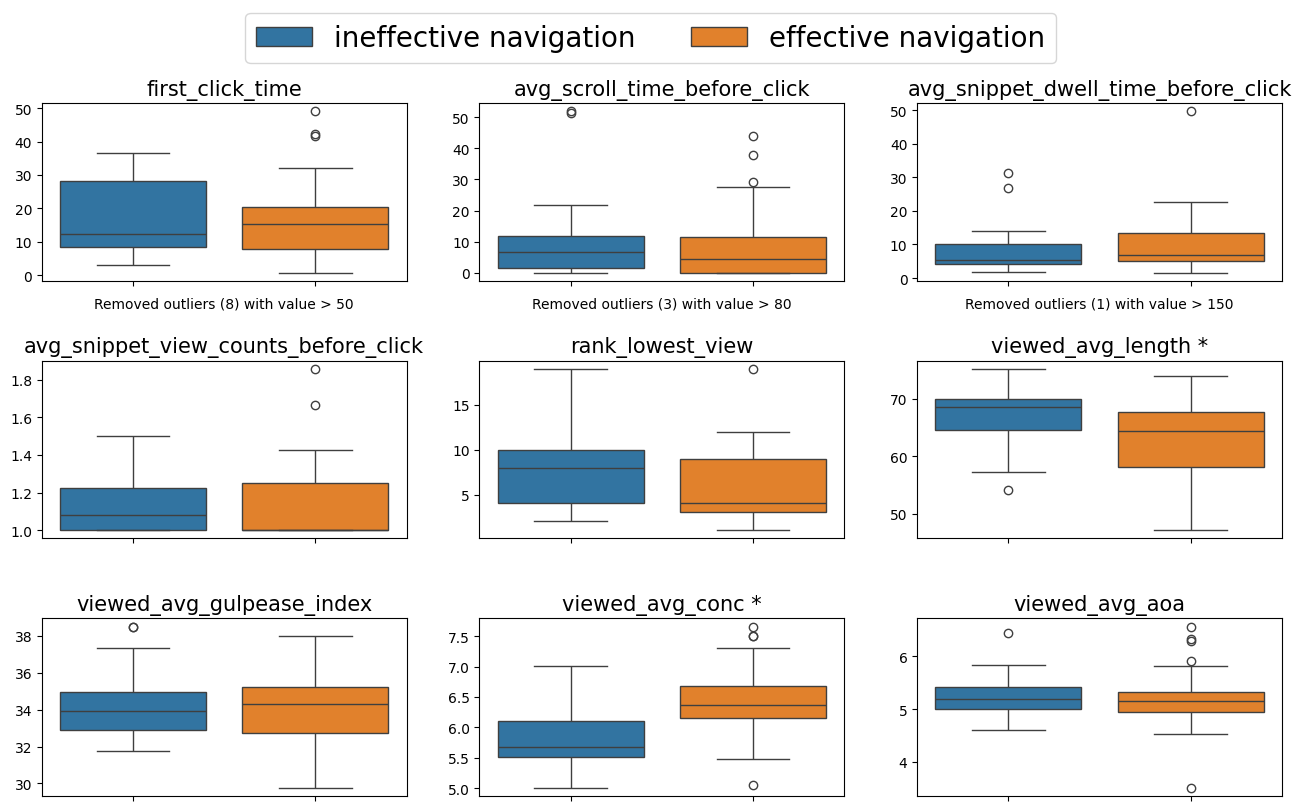

In [6]:
from driver import get_boxplots

get_boxplots(df=navigation_quality, search_stage="results_navigation_nav_eff", categories=categories, group="effective_nav", artefact="navigation", n_cols=3, n_rows=3, stats_df=sig_test_results_nav_eff)

#### w.r.t tail ratio

In [7]:
len(navigation_quality), len(navigation_quality.loc[pd.notna(navigation_quality["effective_nav_pt2"])]), len(navigation_quality.loc[navigation_quality["effective_nav_pt2"]==1])

(103, 59, 47)

In [8]:
from driver import get_significance

desc_stats_df_tail_ratio, sig_test_results_tail_ratio = get_significance(df=navigation_quality, effective_label="effective_nav_pt2", search_stage="results_navigation_tail_ratio", categories=categories)
sig_test_results_tail_ratio

,search_stage,characteristic,test_statistic,pval,significant
0,results_navigation_tail_ratio,first_click_time,2.146000,0.5498,False
1,results_navigation_tail_ratio,avg_scroll_time_before_click,-0.833067,0.8406,False
2,results_navigation_tail_ratio,avg_snippet_dwell_time_before_click,-1.736067,0.1512,False
3,results_navigation_tail_ratio,avg_snippet_view_counts_before_click,0.009722,0.9810,False
4,results_navigation_tail_ratio,rank_lowest_view,2.000000,0.4766,False
5,results_navigation_tail_ratio,viewed_avg_length,4.771229,0.0086,True
6,results_navigation_tail_ratio,viewed_avg_gulpease_index,0.000000,0.9524,False
7,results_navigation_tail_ratio,viewed_avg_conc,-0.686167,0.0470,True
8,results_navigation_tail_ratio,viewed_avg_aoa,-0.022256,0.7402,False


In [9]:
desc_stats_df_tail_ratio

,search_stage,characteristic,ineffective_median,ineffective_MAD,effective_median,effective_MAD
0,results_navigation_tail_ratio,first_click_time,21.026000,12.418500,18.880000,10.493000
1,results_navigation_tail_ratio,avg_scroll_time_before_click,6.826933,4.597300,7.660000,7.652000
2,results_navigation_tail_ratio,avg_snippet_dwell_time_before_click,5.079933,1.588311,6.816000,2.849435
3,results_navigation_tail_ratio,avg_snippet_view_counts_before_click,1.059722,0.050000,1.050000,0.050000
4,results_navigation_tail_ratio,rank_lowest_view,8.500000,2.000000,6.500000,3.500000
5,results_navigation_tail_ratio,viewed_avg_length,69.511051,1.570912,64.739822,5.111484
6,results_navigation_tail_ratio,viewed_avg_gulpease_index,33.950000,1.431818,33.950000,1.121429
7,results_navigation_tail_ratio,viewed_avg_conc,5.578125,0.511458,6.264292,0.310488
8,results_navigation_tail_ratio,viewed_avg_aoa,5.155778,0.150532,5.178033,0.253194


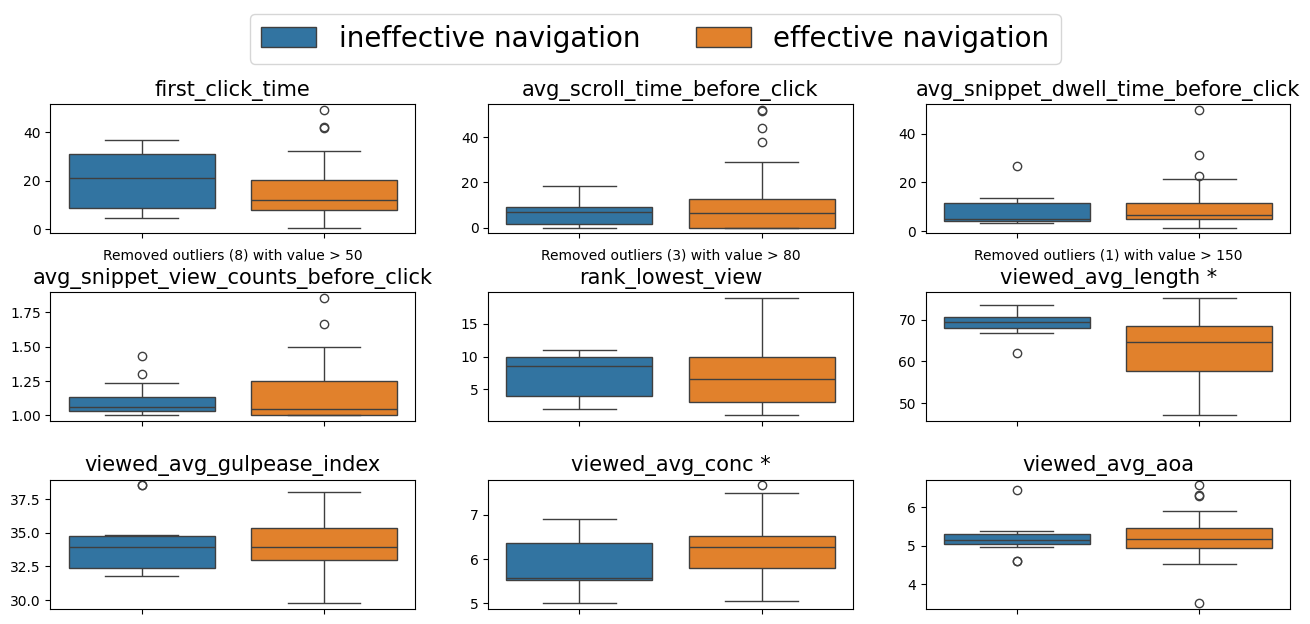

In [10]:
from driver import get_boxplots

get_boxplots(df=navigation_quality, search_stage="results_navigation_tail_ratio", categories=categories, group="effective_nav_pt2", artefact="navigation", n_cols=3, n_rows=4, stats_df=sig_test_results_tail_ratio)